# Proyecto 12 – Pasos 7 y 8: Baseline y modelo final
Se comparan dos referencias sencillas (baseline) con el modelo final y se guarda el modelo versionado para la API.

| Modelo | Tipo | Para qué |
|---|---|---|
| Reglas RD-01 a RD-04 | Baseline 1 | Lo que haría el motor de reglas solo |
| Isolation Forest | Baseline 2 (no supervisado) | Detección de anomalías clásica, sin usar etiquetas |
| HistGradientBoosting | Modelo final (supervisado) | Aprende de las etiquetas `es_fraude` |

**Versión 1.1.0** (ver `03_experimentos.ipynb`): se agregan 4 variables derivadas de los mismos campos de la API (`log_monto_promedio_30d`, `log_monto_promedio_categoria`, `ratio_categoria_vs_30d`, `hora_decimal`) y el umbral se elige por tasa de falsos positivos en valid. El contrato de la API no cambia.

**Métricas (paso 15):** PR-AUC, precision@K, falsos positivos con el umbral elegido. Todas se calculan en **test**, que no se usa para entrenar ni para elegir nada.

In [1]:
import json
from datetime import datetime
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest
from sklearn.metrics import average_precision_score, precision_recall_curve, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

import variables as V

SEMILLA = 42
VERSION_MODELO = "1.1.0"
BASE = Path("C:/Users/isalo/Desktop/universidad/9.Semestre_9/Big data/Proyecto Final")
RUTA_PROCESADOS = BASE / "datos_procesados"
RUTA_MODELOS = BASE / "modelos"; RUTA_MODELOS.mkdir(exist_ok=True)
np.random.seed(SEMILLA)

train = pd.read_parquet(RUTA_PROCESADOS / "train.parquet")
valid = pd.read_parquet(RUTA_PROCESADOS / "valid.parquet")
test = pd.read_parquet(RUTA_PROCESADOS / "test.parquet")

X_train, y_train = train[V.COLUMNAS_API], train["es_fraude"].values
X_valid, y_valid = valid[V.COLUMNAS_API], valid["es_fraude"].values
X_test, y_test = test[V.COLUMNAS_API], test["es_fraude"].values
for n, y in [("train", y_train), ("valid", y_valid), ("test", y_test)]:
    print(f"{n}: {len(y):,} filas, {y.sum():,} fraudes ({y.mean():.3%})")

train: 1,037,340 filas, 5,968 fraudes (0.575%)
valid: 259,335 filas, 1,538 fraudes (0.593%)
test: 555,719 filas, 2,145 fraudes (0.386%)


In [2]:
def precision_at_k(y, puntaje, k):
    """De las k transacciones con mayor puntaje, qué proporción es fraude."""
    k = min(k, len(y))
    idx = np.argsort(-puntaje)[:k]
    return y[idx].mean()

def metricas(nombre, y, puntaje, umbral=None):
    m = {"modelo": nombre,
         "pr_auc": average_precision_score(y, puntaje),
         "precision@100": precision_at_k(y, puntaje, 100),
         "precision@500": precision_at_k(y, puntaje, 500)}
    if umbral is not None:
        pred = (puntaje >= umbral).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
        m.update({"umbral": umbral, "recall": tp / max(tp + fn, 1), "precision": tp / max(tp + fp, 1),
                  "falsos_positivos": int(fp), "tasa_alertas": pred.mean()})
    return m

print("PR-AUC de un modelo aleatorio = tasa de fraude en test:", round(y_test.mean(), 5))

PR-AUC de un modelo aleatorio = tasa de fraude en test: 0.00386


## Baseline 1: reglas de detección
Puntaje = suma ponderada de las reglas del documento de modelado (RD-01 es crítica, pesa más).

In [3]:
def puntaje_reglas(X):
    v = V.construir_variables(X)
    rd01 = (v["ratio_monto_30d"] > 5).astype(int)                                  # crítica
    rd02 = (np.expm1(v["log_segundos_desde_ultima"]) < 120).astype(int)
    rd03 = (((v["hora"] >= 22) | (v["hora"] < 4)) & (v["ratio_monto_categoria"] > 5)).astype(int)
    rd04 = v["primera_vez_categoria"].astype(int)
    return ((3 * rd01 + rd02 + rd03 + rd04) / 6).values

p_reglas_valid = puntaje_reglas(X_valid)
p_reglas_test = puntaje_reglas(X_test)
pd.DataFrame([metricas("Reglas (valid)", y_valid, p_reglas_valid)]).round(4)

,modelo,pr_auc,precision@100,precision@500
0,Reglas (valid),0.1712,0.47,0.418


## Baseline 2: Isolation Forest (detección de anomalías no supervisada)
No usa las etiquetas: aprende qué es "normal" y da puntaje alto a lo que se aleja de eso. Se entrena con una muestra para que sea rápido.

In [4]:
def preprocesador(escalar):
    num = StandardScaler() if escalar else "passthrough"
    return ColumnTransformer([
        ("num", num, V.VARIABLES_NUMERICAS),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), V.VARIABLES_CATEGORICAS),
    ])

iforest = Pipeline([
    ("variables", FunctionTransformer(V.construir_variables)),
    ("prep", preprocesador(escalar=True)),
    ("modelo", IsolationForest(n_estimators=200, random_state=SEMILLA, n_jobs=-1)),
])
muestra = X_train.sample(n=min(200_000, len(X_train)), random_state=SEMILLA)
iforest.fit(muestra)

p_if_valid = -iforest.score_samples(X_valid)   # más alto = más anómalo
p_if_test = -iforest.score_samples(X_test)
pd.DataFrame([metricas("Isolation Forest (valid)", y_valid, p_if_valid)]).round(4)

,modelo,pr_auc,precision@100,precision@500
0,Isolation Forest (valid),0.2414,0.57,0.446


## Modelo final: HistGradientBoosting
Se prueban pocas combinaciones de hiperparámetros y se elige la de mejor PR-AUC en **valid**. `class_weight="balanced"` compensa el desbalance de clases.

In [5]:
def pipeline_final(learning_rate, max_leaf_nodes):
    return Pipeline([
        ("variables", FunctionTransformer(V.construir_variables)),
        ("prep", preprocesador(escalar=False)),
        ("modelo", HistGradientBoostingClassifier(
            learning_rate=learning_rate, max_leaf_nodes=max_leaf_nodes, max_iter=300,
            class_weight="balanced", early_stopping=True, random_state=SEMILLA)),
    ])

resultados = []
for lr in [0.05, 0.1]:
    for hojas in [31, 63]:
        m = pipeline_final(lr, hojas).fit(X_train, y_train)
        pr = average_precision_score(y_valid, m.predict_proba(X_valid)[:, 1])
        resultados.append({"learning_rate": lr, "max_leaf_nodes": hojas, "pr_auc_valid": pr})
        print(f"lr={lr}, hojas={hojas} -> PR-AUC valid = {pr:.4f}")

mejor = max(resultados, key=lambda r: r["pr_auc_valid"])
print("Mejor configuración:", mejor)

lr=0.05, hojas=31 -> PR-AUC valid = 0.9225


lr=0.05, hojas=63 -> PR-AUC valid = 0.9242


lr=0.1, hojas=31 -> PR-AUC valid = 0.9297


lr=0.1, hojas=63 -> PR-AUC valid = 0.9252
Mejor configuración: {'learning_rate': 0.1, 'max_leaf_nodes': 31, 'pr_auc_valid': 0.9296545370480935}


In [6]:
modelo = pipeline_final(mejor["learning_rate"], mejor["max_leaf_nodes"]).fit(X_train, y_train)
p_valid = modelo.predict_proba(X_valid)[:, 1]
p_test = modelo.predict_proba(X_test)[:, 1]

## Elegir el umbral (en valid)
Se fija la **tasa de falsos positivos** en valid: el umbral deja pasar como máximo el **0,2 %** de las transacciones normales. Este criterio solo depende de cómo se distribuyen las transacciones normales, así que no se mueve cuando cambia la tasa de fraude (en valid es 0,59 % y en test 0,39 %). El criterio anterior (precisión ≥ 0,50) sí dependía de esa tasa.

En `03_experimentos.ipynb` (bloque C, mitades temporales de valid) este punto da precisión ≈ 0,72–0,75 y recall ≈ 0,92: cumple precisión ≥ 0,50 y recall ≥ 0,80 con la mitad de alertas que el umbral anterior. El valor se guarda en la metadata como umbral inicial sugerido para el backend.

In [7]:
TASA_FP_OBJETIVO = 0.002   # máximo 0,2 % de las transacciones normales de valid marcadas como sospechosas

normales = np.sort(p_valid[y_valid == 0])[::-1]
UMBRAL = float(normales[int(TASA_FP_OBJETIVO * len(normales))])

pred_valid = p_valid >= UMBRAL
tp = (pred_valid & (y_valid == 1)).sum(); fp = (pred_valid & (y_valid == 0)).sum()
print(f"Umbral elegido: {UMBRAL:.4f} | precisión valid: {tp / (tp + fp):.3f} | recall valid: {tp / y_valid.sum():.3f} | "
      f"tasa FP valid: {fp / (y_valid == 0).sum():.4f}")

Umbral elegido: 0.9241 | precisión valid: 0.734 | recall valid: 0.925 | tasa FP valid: 0.0020


## Evaluación final en test y comparación con los baselines

In [8]:
umbral_reglas = 3 / 6   # equivale a "se activó la regla crítica"
umbral_if = np.quantile(p_if_valid, 1 - (p_valid >= UMBRAL).mean())  # misma tasa de alertas que el modelo

comparacion = pd.DataFrame([
    metricas("Baseline 1: Reglas", y_test, p_reglas_test, umbral_reglas),
    metricas("Baseline 2: Isolation Forest", y_test, p_if_test, umbral_if),
    metricas("Modelo final: HistGradientBoosting", y_test, p_test, UMBRAL),
]).set_index("modelo")
comparacion.round(4)

,pr_auc,precision@100,precision@500,umbral,recall,precision,falsos_positivos,tasa_alertas
modelo,,,,,,,,
Baseline 1: Reglas,0.1380,0.47,0.360,0.5000,0.4639,0.0961,9360,0.0186
Baseline 2: Isolation Forest,0.1886,0.48,0.404,0.5387,0.4140,0.2567,2571,0.0062
Modelo final: HistGradientBoosting,0.8920,1.00,1.000,0.9241,0.8918,0.6456,1050,0.0053


C:\Users\isalo\anaconda3\envs\proyectoFinal\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


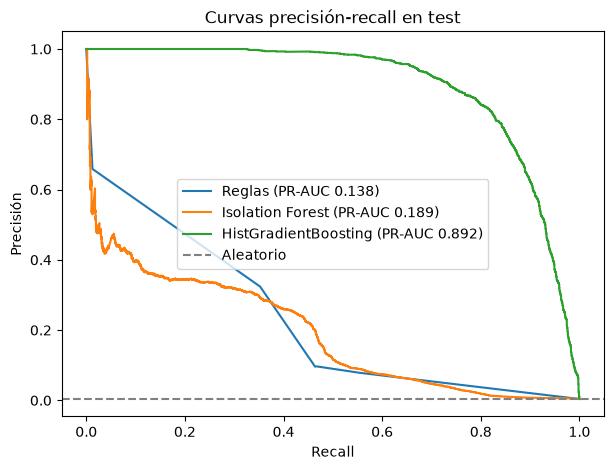

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
for nombre, p in [("Reglas", p_reglas_test), ("Isolation Forest", p_if_test), ("HistGradientBoosting", p_test)]:
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax.plot(rc, pr, label=f"{nombre} (PR-AUC {average_precision_score(y_test, p):.3f})")
ax.axhline(y_test.mean(), ls="--", color="gray", label="Aleatorio")
ax.set_xlabel("Recall"); ax.set_ylabel("Precisión"); ax.set_title("Curvas precisión-recall en test"); ax.legend()
plt.show()

## Análisis de errores
Falsos positivos (normales marcadas como sospechosas) y falsos negativos (fraudes no detectados) con el umbral elegido.

In [10]:
ana = test.assign(puntaje=p_test, pred=(p_test >= UMBRAL).astype(int))
ana = ana.join(V.construir_variables(X_test)[["canal", "hora", "ratio_monto_30d"]])
fp = ana[(ana.pred == 1) & (ana.es_fraude == 0)]
fn = ana[(ana.pred == 0) & (ana.es_fraude == 1)]
print(f"Falsos positivos: {len(fp):,} | Falsos negativos: {len(fn):,}")

cols = ["fecha_hora", "categoria", "canal", "hora", "monto", "ratio_monto_30d", "primera_vez_categoria", "puntaje"]
print("\nFalsos positivos con mayor puntaje:")
display(fp.sort_values("puntaje", ascending=False)[cols].head(5))
print("Fraudes no detectados con menor puntaje:")
display(fn.sort_values("puntaje")[cols].head(5))
print("Recall por categoría:")
display(ana[ana.es_fraude == 1].groupby("categoria")["pred"].mean().sort_values().round(3))

Falsos positivos: 1,050 | Falsos negativos: 232

Falsos positivos con mayor puntaje:


,fecha_hora,categoria,canal,hora,monto,ratio_monto_30d,primera_vez_categoria,puntaje
423145,2020-12-09 22:33:23,compras en línea,en_linea,22,2910075.0,7.614174,0,0.999128
328966,2020-11-10 23:41:43,compras en línea,en_linea,23,3775135.0,7.117340,0,0.999118
500453,2020-11-01 23:28:00,compras en línea,en_linea,23,3355030.0,7.731179,0,0.999054
378698,2020-07-02 23:05:44,compras en línea,en_linea,23,2926245.0,9.126551,0,0.999023
35022,2020-08-17 22:16:21,compras en línea,en_linea,22,3621205.0,17.191376,0,0.999011


Fraudes no detectados con menor puntaje:


,fecha_hora,categoria,canal,hora,monto,ratio_monto_30d,primera_vez_categoria,puntaje
421577,2020-07-27 21:20:53,viajes,otro,21,18410.0,0.093204,0,0.001193
62279,2020-09-14 16:41:37,viajes,otro,16,6965.0,0.024518,0,0.001382
129890,2020-10-12 20:26:12,salud y bienestar,otro,20,76055.0,0.347204,0,0.003780
395125,2020-12-06 13:10:58,salud y bienestar,otro,13,61075.0,0.436712,0,0.004793
173031,2020-10-09 12:15:41,compras diversas en establecimientos,punto_venta,12,177065.0,0.859032,0,0.017101


Recall por categoría:


categoria
alimentación y restaurantes             0.352
viajes                                  0.400
cuidado personal                        0.486
niños y mascotas                        0.508
compras diversas en establecimientos    0.583
salud y bienestar                       0.673
compras de supermercado en línea        0.732
hogar                                   0.761
entretenimiento                         0.932
compras en establecimientos             0.953
compras diversas en línea               0.963
gasolina y transporte                   0.981
compras en línea                        0.994
compras en supermercado                 0.998
Name: pred, dtype: float64

## Experimento de sesgo (insumo para el paso 16)
1. ¿El modelo principal se equivoca más con algún género o grupo de edad?
2. ¿Agregar edad y género mejora el modelo? Si no mejora claramente, se mantiene el modelo sin ellos.

In [11]:
def tasas_por_grupo(df, columna):
    g = df.groupby(columna, observed=True)
    return pd.DataFrame({
        "transacciones": g.size(),
        "tasa_falsos_positivos": g.apply(lambda x: ((x.pred == 1) & (x.es_fraude == 0)).sum() / max((x.es_fraude == 0).sum(), 1)),
        "recall": g.apply(lambda x: ((x.pred == 1) & (x.es_fraude == 1)).sum() / max((x.es_fraude == 1).sum(), 1)),
    }).round(4)

ana["grupo_edad"] = pd.cut(ana["edad"], bins=[0, 30, 45, 60, 120], labels=["<30", "30-44", "45-59", "60+"])
display(tasas_por_grupo(ana, "genero"))
display(tasas_por_grupo(ana, "grupo_edad"))

,transacciones,tasa_falsos_positivos,recall
genero,,,
F,304886,0.0023,0.8505
M,250833,0.0014,0.9409


,transacciones,tasa_falsos_positivos,recall
grupo_edad,,,
<30,106622,0.0019,0.9327
30-44,187123,0.0020,0.8574
45-59,146195,0.0017,0.8764
60+,115779,0.0019,0.9246


In [12]:
def variables_con_demografia(X):
    v = V.construir_variables(X)
    v["edad"] = X["edad"].values
    v["genero"] = X["genero"].astype(str).values
    return v

cols_exp = V.COLUMNAS_API + ["edad", "genero"]
modelo_exp = Pipeline([
    ("variables", FunctionTransformer(variables_con_demografia)),
    ("prep", ColumnTransformer([
        ("num", "passthrough", V.VARIABLES_NUMERICAS + ["edad"]),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), V.VARIABLES_CATEGORICAS + ["genero"]),
    ])),
    ("modelo", HistGradientBoostingClassifier(
        learning_rate=mejor["learning_rate"], max_leaf_nodes=mejor["max_leaf_nodes"], max_iter=300,
        class_weight="balanced", early_stopping=True, random_state=SEMILLA)),
]).fit(train[cols_exp], y_train)
p_exp = modelo_exp.predict_proba(valid[cols_exp])[:, 1]
print(f"PR-AUC valid sin demografía: {average_precision_score(y_valid, p_valid):.4f}")
print(f"PR-AUC valid con edad y género: {average_precision_score(y_valid, p_exp):.4f}")

PR-AUC valid sin demografía: 0.9297
PR-AUC valid con edad y género: 0.9531


**Conclusión del experimento de sesgo (modelo 1.1.0, umbral 0,9241, test):**

1. **Errores por grupo.** Las tasas de falsos positivos son bajas en todos los grupos (0,14 %–0,23 %). La diferencia que más pesa está en el recall por género: el modelo detecta el **94,1 %** de los fraudes contra hombres y el **85,1 %** de los fraudes contra mujeres (9 puntos de diferencia). Las mujeres además tienen una tasa de falsos positivos algo mayor (0,23 % frente a 0,14 %). Por edad, el recall va de 85,7 % (30–44 años) a 93,3 % (<30 años), y la tasa de falsos positivos es casi igual en todos los grupos (0,17 %–0,20 %). Con el umbral anterior (v1.0.0, más permisivo) la brecha de recall por género era menor, 91,3 % frente a 97,5 % (6 puntos): el umbral estricto reduce las alertas a la mitad, pero amplía esa brecha. Una explicación probable es que el modelo detecta peor el fraude en algunas categorías (alimentación 35 %, viajes 40 %, cuidado personal 49 %) y la mezcla de categorías cambia entre grupos. Hay que vigilar esta brecha en producción.
2. **¿Agregar edad y género mejora el modelo?** Sí: el PR-AUC en valid sube de 0,9297 a 0,9531. Aun así **no se agregan al modelo principal**. Serían variables sensibles: el modelo trataría distinto a dos clientes con la misma transacción solo por su género o su edad, y en datos simulados (Sparkov) esa ganancia puede reflejar cómo se generaron los perfiles de fraude más que un patrón real. Se mantiene el modelo sin datos demográficos.

## Guardar el modelo versionado
Se guarda el **pipeline completo** (construcción de variables + preprocesamiento + modelo), así la API solo tiene que pasarle los campos que envía el backend. La API debe tener `variables.py` en la misma carpeta para poder cargarlo.

In [13]:
joblib.dump(modelo, RUTA_MODELOS / "fraud_model.joblib")

fila_final = comparacion.loc["Modelo final: HistGradientBoosting"]
metadata_modelo = {
    "version_modelo": VERSION_MODELO,
    "algoritmo": "HistGradientBoostingClassifier",
    "hiperparametros": {"learning_rate": mejor["learning_rate"], "max_leaf_nodes": mejor["max_leaf_nodes"],
                        "max_iter": 300, "class_weight": "balanced"},
    "semilla": SEMILLA,
    "fecha_entrenamiento": datetime.now().isoformat(timespec="seconds"),
    "version_sklearn": sklearn.__version__,
    "columnas_entrada": V.COLUMNAS_API,
    "variables_modelo": V.VARIABLES_NUMERICAS + V.VARIABLES_CATEGORICAS,
    "umbral_sugerido": round(UMBRAL, 4),
    "criterio_umbral": f"tasa de falsos positivos <= {TASA_FP_OBJETIVO} en valid",
    "metricas_test": {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v)
                      for k, v in fila_final.dropna().items()},
}
(RUTA_MODELOS / "metadata_modelo.json").write_text(json.dumps(metadata_modelo, indent=2, ensure_ascii=False))
print(json.dumps(metadata_modelo, indent=2, ensure_ascii=False))

{
  "version_modelo": "1.1.0",
  "algoritmo": "HistGradientBoostingClassifier",
  "hiperparametros": {
    "learning_rate": 0.1,
    "max_leaf_nodes": 31,
    "max_iter": 300,
    "class_weight": "balanced"
  },
  "semilla": 42,
  "fecha_entrenamiento": "2026-11-21T20:39:21",
  "version_sklearn": "1.9.1",
  "columnas_entrada": [
    "monto",
    "fecha_hora",
    "categoria",
    "monto_promedio_30d",
    "monto_promedio_categoria",
    "primera_vez_categoria",
    "segundos_desde_ultima"
  ],
  "variables_modelo": [
    "log_monto",
    "hora",
    "dia_semana",
    "ratio_monto_30d",
    "ratio_monto_categoria",
    "primera_vez_categoria",
    "log_segundos_desde_ultima",
    "log_monto_promedio_30d",
    "log_monto_promedio_categoria",
    "ratio_categoria_vs_30d",
    "hora_decimal",
    "categoria",
    "canal"
  ],
  "umbral_sugerido": 0.9241,
  "criterio_umbral": "tasa de falsos positivos <= 0.002 en valid",
  "metricas_test": {
    "pr_auc": 0.892,
    "precision@100": 1.0,
  

## Prueba: cargar el modelo como lo hará la API

In [14]:
modelo_cargado = joblib.load(RUTA_MODELOS / "fraud_model.joblib")
peticion = {
    "transaccion_id": "TX-0083726",
    "monto": 245800,
    "fecha_hora": "2026-11-21T10:30:00",
    "categoria": "compras en línea",
    "monto_promedio_30d": 62400,
    "monto_promedio_categoria": 15200,
    "primera_vez_categoria": True,
    "segundos_desde_ultima": 540,
}
entrada = pd.DataFrame([{k: peticion[k] for k in V.COLUMNAS_API}])
respuesta = {"transaccion_id": peticion["transaccion_id"],
             "puntaje_riesgo": round(float(modelo_cargado.predict_proba(entrada)[0, 1]), 4),
             "version_modelo": VERSION_MODELO}
respuesta

{'transaccion_id': 'TX-0083726',
 'puntaje_riesgo': 0.0024,
 'version_modelo': '1.1.0'}